In [ ]:
from matplotlib import pyplot as plt

x = [i for i in range(10)]
y = [i**2+5 for i in range(10)]

plt.plot(x, y)
plt.errorbar(x, y, marker="o", linestyle="none", xerr=0.25, yerr=5)
plt.xlim([0, 10]) # добавляем подписи по оси x
plt.title(r'График зависимости y от $\epsilon$') # добавляем заголовок к графику
plt.xlabel(r'$\epsilon$') # добавляем подписи по оси x
plt.ylabel('y') # добавляем подписи по оси y
plt.minorticks_on()
plt.grid()
plt.grid(which="minor", linestyle=":")
plt.savefig("plot.pdf")
plt.show()


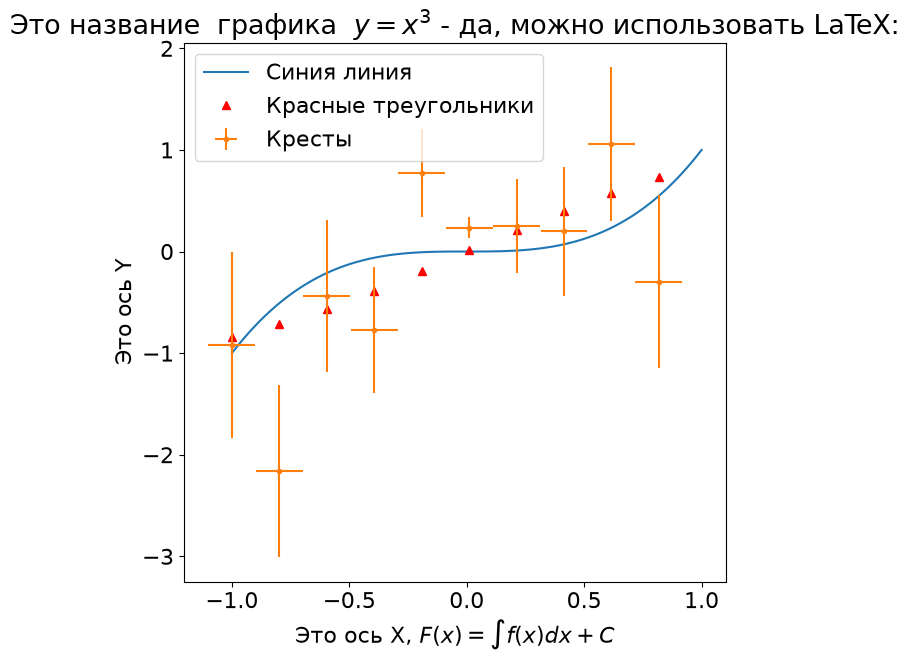

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['font.size'] = 16 # Управление стилем, в данном случаем - размером шрифта 
 # Создаем фигуру
plt.figure(figsize=(7,7))

# Подписываем оси и график
plt.title(r"Это название  графика  $y = x^3$ - да, можно использовать LaTeX:")
plt.ylabel("Это ось Y")
plt.xlabel(r"Это ось X, $F(x) = \int f(x) dx + C$")



# Добавляем данные
x = np.linspace(-1,1,100)
y = x**3
plt.plot(x,y, label="Синия линия")

# Еще данные
x2 = x[::10]
y2 = np.sin(x2)
plt.plot(x2,y2, 'r^', label='Красные треугольники')
# 'r^' - задает стиль линии - красные (red) треугольники (^), подробнее в документации

# Данные с ошибками
mu = np.sin(x2)
sigma = np.abs(mu)**0.5
y2 = np.random.normal(mu, sigma)
# Можно рисовать ошибки
plt.errorbar(x2,y2, yerr=sigma, xerr=0.1, fmt='.', label='Кресты') 

# Активируем сетку
#plt.grid(b=True, which='major', axis='both', alpha=1)
# plt.grid(b=True, which='minor', axis='both', alpha=0.5)

# Активируем легенду графика
plt.legend()
# Внимание, запускаете вашу программу как сценарий, то что бы показать график
# Используйте эту команду
# plt.show()
# Сохраняем изображение в текущую директорию
plt.savefig('example.png')

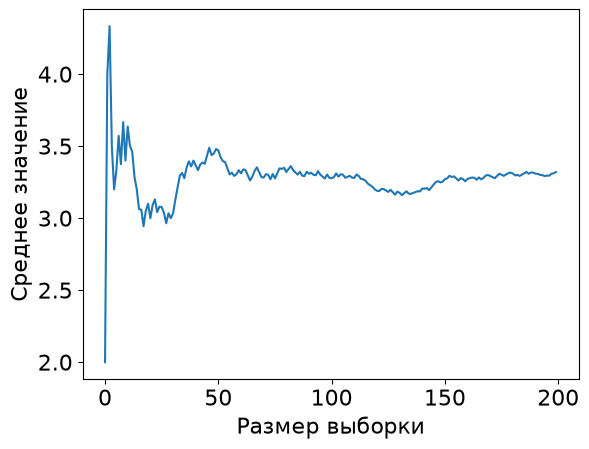

In [23]:
n = 200 # Размер выборки
np.random.seed(10) # Фиксирует состояниее ГПСЧ, для повторяемости случайных последовательностей
sample = np.random.randint(1,7,size=n) # Правая граница не включается
means = np.cumsum(sample)/np.arange(1, n+1)

plt.ylabel("Среднее значение")
plt.xlabel('Размер выборки')
plt.plot(means);

[3.16469707 4.42800282 4.38051854]
[[ 6.74246530e-03 -1.84713623e-18 -6.86732577e-02]
 [-1.84713623e-18  5.32737999e-02  4.18743318e-18]
 [-6.86732577e-02  4.18743318e-18  1.24205336e+00]]
a = 3.16 ± 0.082
b = 4.43 ± 0.23
c = 4.38 ± 1.11


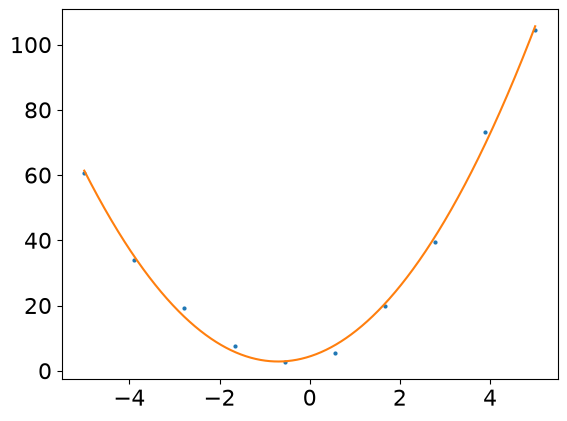

In [24]:
z = np.linspace(-5, 5, 1000)

# Данные
x = np.linspace(-5, 5, 10)
y = 3*x**2 + 5*x + 1 + 10*np.random.sample(len(x))

# Фитируем многочленом второй степени с рассчетом матрицы ошибок
params, cov = np.polyfit(x, y, 2, cov=True)
plt.plot(x, y, 'o', markersize=2)
plt.plot(z, params[0] * z**2 + params[1] * z + params[2])
print(params)
print(cov)
print(f"a = {params[0]:.3} \u00B1 {np.sqrt(cov[0][0]):.2}")
print(f"b = {params[1]:.3} \u00B1 {np.sqrt(cov[1][1]):.2}")
print(f"c = {params[2]:.3} \u00B1 {np.sqrt(cov[2][2]):.3}")

[ 45.40114487 341.39906705  88.62304249]
[[17.3590603  -6.77377977  0.75023037]
 [-6.77377977  4.29974602 -2.95671202]
 [ 0.75023037 -2.95671202 10.18644963]]
a = 45.4 ± 4.2
b = 3.41e+02 ± 2.1
c = 88.6 ± 3.19


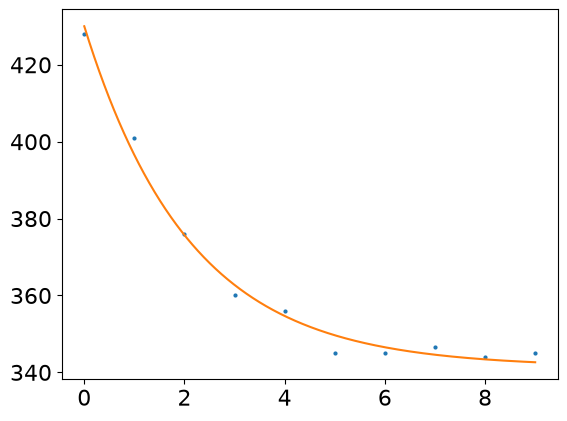

In [25]:
from scipy.optimize import curve_fit

# Функция, которой нужно приблизить зависимость
def fit_func(x, a, b, c):
    return c*np.exp(-x*1.9*11.34/a)+b

# Данные
z = np.linspace(0, 9, 1000)
x = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
y = [428.,  401.,  376.,  360.,  356.,  345.,  345.,  346.5, 344.,  345.]

# Получение параметров и ошибок по функции и точкам, с указанием начальных параметров
params, cov = curve_fit(fit_func, x, y, p0 = [30, 345, 100])
print(params)
print(cov)

plt.plot(x, y, 'o', markersize=2)
plt.plot(z, fit_func(z, params[0], params[1], params[2]))

print(f"a = {params[0]:.3} \u00B1 {np.sqrt(cov[0][0]):.2}")
print(f"b = {params[1]:.3} \u00B1 {np.sqrt(cov[1][1]):.2}")
print(f"c = {params[2]:.3} \u00B1 {np.sqrt(cov[2][2]):.3}")